# Parkha Kashaf Zeb
# 11/18/2026
# Exploratory Data Analysis (EDA)

This notebook explores the cleaned e-commerce dataset using Pandas and NumPy to understand sales, orders, products, and customer patterns.

In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv(
    "../outputs/processed/pakistan_ecommerce_cleaned.csv",
    low_memory=False
)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (584524, 21)


,item_id,status,created_at,sku,price,qty_ordered,grand_total,increment_id,category_name_1,sales_commission_code,...,payment_method,Working Date,BI Status,MV,Year,Month,Customer Since,M-Y,FY,Customer ID
0,211131,complete,2016-07-01,kreations_YI 06-L,1950.0,1,1950.0,100147443,Women's Fashion,NaN,...,cod,2016-07-01,NaN,"1,950",2016,7,2016-07-01,7-2016,FY17,1.0
1,211133,canceled,2016-07-01,kcc_Buy 2 Frey Air Freshener & Get 1 Kasual Bo...,240.0,1,240.0,100147444,Beauty & Grooming,NaN,...,cod,2016-07-01,Gross,240,2016,7,2016-07-01,7-2016,FY17,2.0
2,211134,canceled,2016-07-01,Ego_UP0017-999-MR0,2450.0,1,2450.0,100147445,Women's Fashion,NaN,...,cod,2016-07-01,Gross,"2,450",2016,7,2016-07-01,7-2016,FY17,3.0
3,211135,complete,2016-07-01,kcc_krone deal,360.0,1,60.0,100147446,Beauty & Grooming,R-FSD-52352,...,cod,2016-07-01,Net,360,2016,7,2016-07-01,7-2016,FY17,4.0
4,211136,order_refunded,2016-07-01,BK7010400AG,555.0,2,1110.0,100147447,Soghaat,NaN,...,cod,2016-07-01,Valid,"1,110",2016,7,2016-07-01,7-2016,FY17,5.0


## 1. Numerical Summary Statistics

Analyze numerical columns using Pandas to understand their count, mean, standard deviation, minimum, maximum, and quartiles.

In [3]:
numeric_columns = [
    "price",
    "qty_ordered",
    "grand_total",
    "discount_amount"
]

df[numeric_columns].describe()

,price,qty_ordered,grand_total,discount_amount
count,5.845240e+05,584524.000000,5.845240e+05,584524.000000
mean,6.348748e+03,1.296388,8.530619e+03,499.492775
std,1.494927e+04,3.996061,6.132081e+04,1506.943046
min,0.000000e+00,1.000000,-1.594000e+03,-599.500000
25%,3.600000e+02,1.000000,9.450000e+02,0.000000
50%,8.990000e+02,1.000000,1.960400e+03,0.000000
75%,4.070000e+03,1.000000,6.999000e+03,160.500000
max,1.012626e+06,1000.000000,1.788800e+07,90300.000000


### Observations

- The median quantity ordered is 1, indicating that most order items have a quantity of one.
- The median product price is 899, while the mean is 6348.75, suggesting a right-skewed distribution.
- The median discount amount is zero, indicating that at least half of the records have no discount.
- Extreme values are present in price, quantity, and grand_total.
- Negative grand totals and discount amounts were identified during cleaning and preserved for further interpretation.

In [ ]:
# Analyze categorical columns
categorical_columns = [
    "status",
    "category_name_1",
    "payment_method"
]

for column in categorical_columns:
    print(f"\nTop 10 values in {column}:")
    print(df[column].value_counts().head(10))


Top 10 values in status:
status
complete          233685
canceled          201249
received           77290
order_refunded     59529
refund              8050
cod                 2859
paid                1159
closed               494
payment_review        57
pending               48
Name: count, dtype: int64

Top 10 values in category_name_1:
category_name_1
Mobiles & Tablets    115710
Men's Fashion         92221
Women's Fashion       59721
Appliances            52413
Superstore            43613
Beauty & Grooming     41496
Soghaat               34011
Others                29218
Home & Living         26504
Entertainment         26326
Name: count, dtype: int64

Top 10 values in payment_method:
payment_method
cod                271960
Payaxis             97641
Easypay             82900
jazzwallet          35145
easypay_voucher     31176
bankalfalah         23065
jazzvoucher         15633
Easypay_MA          14028
customercredit       7555
apg                  1758
Name: count, dtype: int64

### Categorical Analysis Observations

- Complete is the most frequent order status, followed by canceled.
- Mobiles & Tablets is the most frequently recorded product category.
- Men's Fashion and Women's Fashion are also among the leading categories.
- Cash on Delivery (COD) is the most frequently used payment method.
- Payaxis and Easypay are the second and third most frequent payment methods.

## 2. Data Visualizations

Visualize the dataset to identify patterns and distributions in product categories, order statuses, and product prices.

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

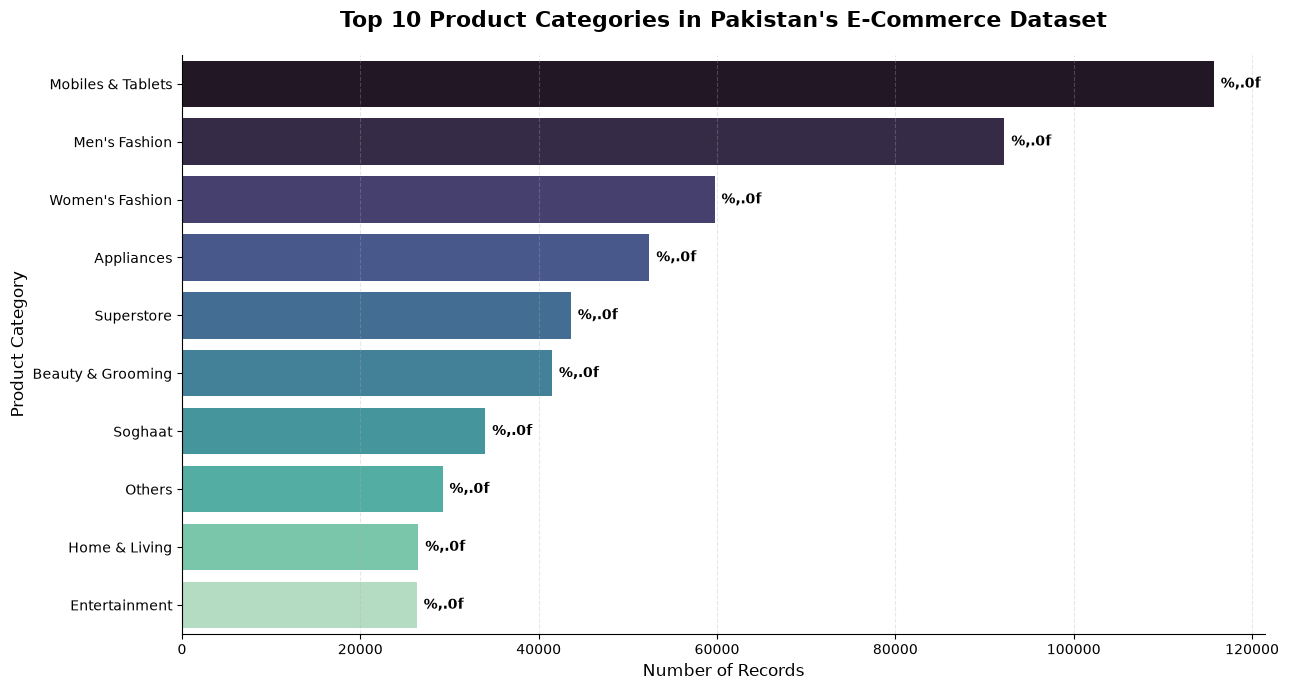

In [ ]:
plt.figure(figsize=(13, 7))

top_categories = df["category_name_1"].value_counts().head(10)

ax = sns.barplot(
    x=top_categories.values,
    y=top_categories.index,
    hue=top_categories.index,
    palette="mako",
    legend=False
)

# Display values on bars
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%,.0f",
        padding=5,
        fontsize=10,
        fontweight="bold"
    )

plt.title(
    "Top 10 Product Categories in Pakistan's E-Commerce Dataset",
    fontsize=16,
    fontweight="bold",
    pad=20
)

plt.xlabel("Number of Records", fontsize=12)
plt.ylabel("Product Category", fontsize=12)

plt.grid(axis="x", linestyle="--", alpha=0.3)
sns.despine()
plt.tight_layout()
plt.show()
#the graph shows which categories are most represented in the dataset, not necessarily which categories sold the most.

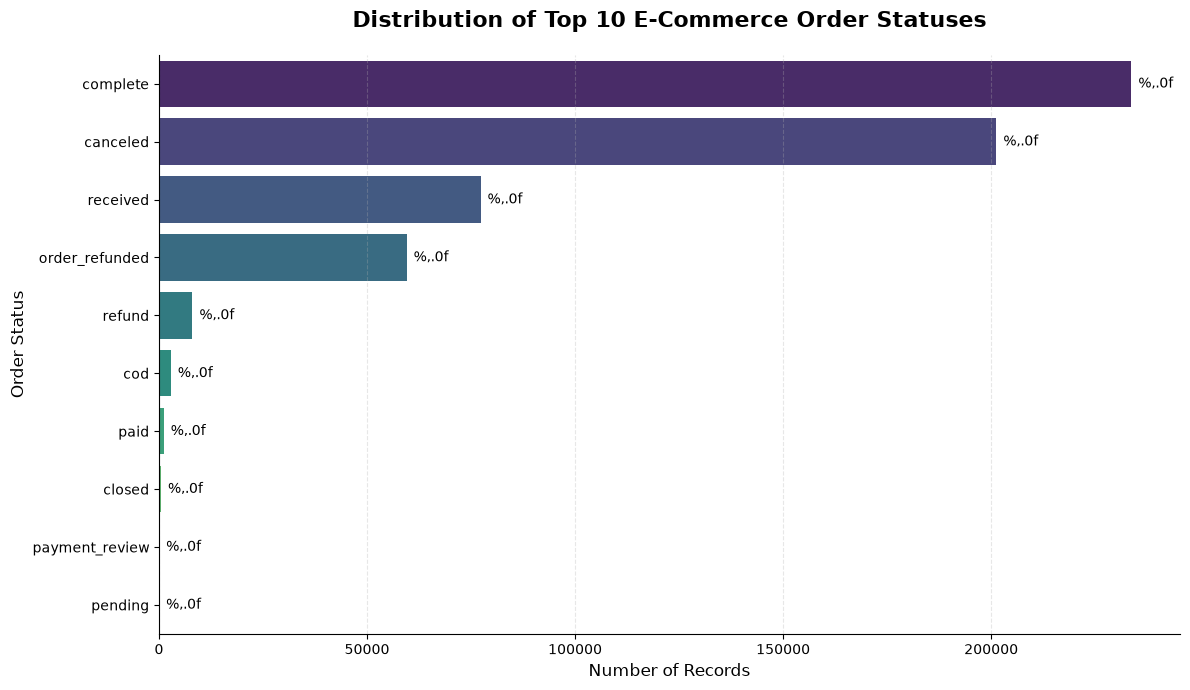

In [ ]:
status_counts = df["status"].value_counts().head(10)

plt.figure(figsize=(12, 7))

ax = sns.barplot(
    x=status_counts.values,
    y=status_counts.index,
    hue=status_counts.index,
    palette="viridis",
    legend=False
)

# Add value labels
for container in ax.containers:
    ax.bar_label(container, fmt="%,.0f", padding=5, fontsize=10)

plt.title(
    "Distribution of Top 10 E-Commerce Order Statuses",
    fontsize=16,
    fontweight="bold",
    pad=20
)

plt.xlabel("Number of Records", fontsize=12)
plt.ylabel("Order Status", fontsize=12)

plt.grid(axis="x", linestyle="--", alpha=0.3)
sns.despine()
plt.tight_layout()
plt.show()

In [20]:
prices = pd.to_numeric(df["price"], errors="coerce").dropna()

print(prices.describe(percentiles=[0.5, 0.9, 0.99]))
print("Zero prices:", (prices == 0).sum())

count    5.845240e+05
mean     6.348748e+03
std      1.494927e+04
min      0.000000e+00
50%      8.990000e+02
90%      1.890000e+04
99%      8.377000e+04
max      1.012626e+06
Name: price, dtype: float64
Zero prices: 2232


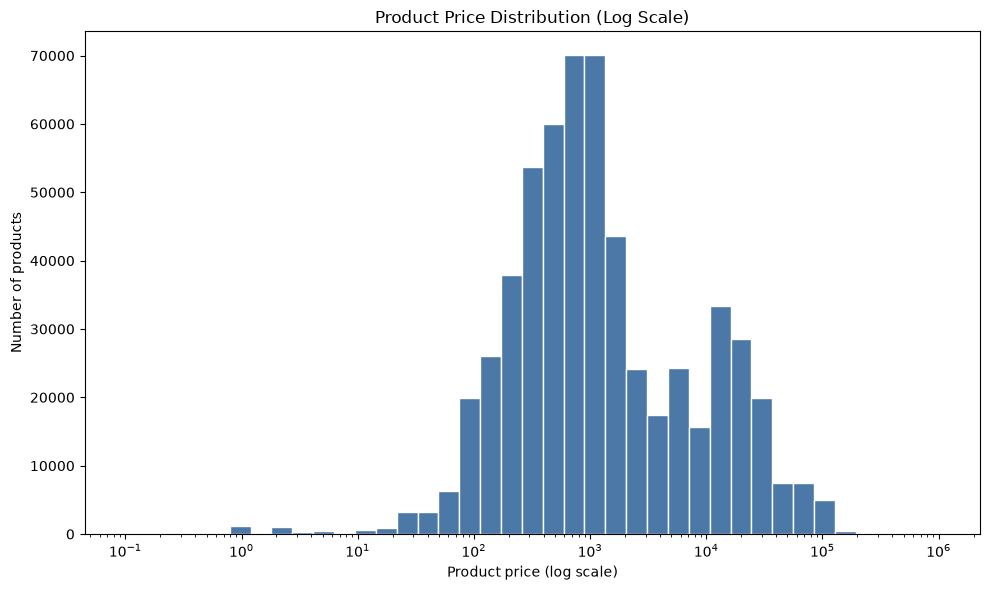

Zero-price records not shown: 2232


In [25]:
prices = pd.to_numeric(df["price"], errors="coerce").dropna()
positive_prices = prices[prices > 0]

bins = np.logspace(
    np.log10(positive_prices.min()),
    np.log10(positive_prices.max()),
    40,
)

fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(positive_prices, bins=bins, color="#4C78A8", edgecolor="white")
ax.set_xscale("log")
ax.set_title("Product Price Distribution (Log Scale)")
ax.set_xlabel("Product price (log scale)")
ax.set_ylabel("Number of products")
plt.tight_layout()
plt.show()

print("Zero-price records not shown:", (prices == 0).sum())

## 3. SQL Analysis Using SQLite

SQLite is used to perform SQL queries on the cleaned e-commerce dataset and extract business insights.

In [26]:
import sqlite3

conn = sqlite3.connect(":memory:")

df.to_sql("ecommerce", conn, index=False, if_exists="replace")

print("Dataset successfully loaded into SQLite!")

Dataset successfully loaded into SQLite!


### Query 1: Top 5 Product Categories

In [ ]:
# Find the five most common product categories

query = """
SELECT
    category_name_1,
    COUNT(*) AS total_records
FROM ecommerce
GROUP BY category_name_1
ORDER BY total_records DESC
LIMIT 5;
"""

pd.read_sql_query(query, conn)

,category_name_1,total_records
0,Mobiles & Tablets,115710
1,Men's Fashion,92221
2,Women's Fashion,59721
3,Appliances,52413
4,Superstore,43613


**Insight:** Mobiles & Tablets has the highest number of records (115,710), followed by Men's Fashion (92,221). This indicates that these categories have the largest representation in the dataset.

### Query 2: Order Status Distribution

In [28]:
query = """
SELECT
    status,
    COUNT(*) AS total_orders
FROM ecommerce
GROUP BY status
ORDER BY total_orders DESC;
"""

pd.read_sql_query(query, conn)

,status,total_orders
0,complete,233685
1,canceled,201249
2,received,77290
3,order_refunded,59529
4,refund,8050
5,cod,2859
6,paid,1159
7,closed,494
8,payment_review,57
9,pending,48


**Insights:**
- Complete is the most frequent order status, with 233,685 records.
- Canceled orders are the second most frequent, with 201,249 records.
- Received and order_refunded are also significant categories.
- There are 19 records with missing order status.

### Query 3: Payment Method Analysis

In [29]:
query = """
SELECT
    payment_method,
    COUNT(*) AS total_records
FROM ecommerce
GROUP BY payment_method
ORDER BY total_records DESC
LIMIT 10;
"""

pd.read_sql_query(query, conn)

,payment_method,total_records
0,cod,271960
1,Payaxis,97641
2,Easypay,82900
3,jazzwallet,35145
4,easypay_voucher,31176
5,bankalfalah,23065
6,jazzvoucher,15633
7,Easypay_MA,14028
8,customercredit,7555
9,apg,1758


**Insights:**
- Cash on Delivery (COD) is the most frequently used payment method, with 271,960 records.
- Payaxis and Easypay are the second and third most frequently used methods.
- COD represents approximately 46.5% of all dataset records.
- Digital payment methods are also represented across several providers.

### Query 4: Monthly Sales Analysis

In [30]:
query = """
SELECT
    Year,
    Month,
    SUM(grand_total) AS total_sales
FROM ecommerce
GROUP BY Year, Month
ORDER BY Year, Month;
"""

pd.read_sql_query(query, conn)

,Year,Month,total_sales
0,2016,7,4.329195e+07
1,2016,8,5.623573e+07
2,2016,9,9.030933e+07
3,2016,10,9.806605e+07
4,2016,11,2.683045e+08
5,2016,12,8.937768e+07
6,2017,1,1.189482e+08
7,2017,2,8.912620e+07
8,2017,3,1.402030e+08
9,2017,4,1.609884e+08


**Insights:**
- November 2017 recorded the highest total grand_total, approximately 799.58 million.
- May 2018 recorded approximately 459.22 million.
- March 2018 recorded approximately 420.14 million.
- July 2016 recorded the lowest total among the displayed months.
- Monthly transaction totals fluctuate considerably over the dataset period.

### Query 5: Top 10 Products by Quantity Ordered

In [32]:
query = """
SELECT
    sku,
    SUM(qty_ordered) AS total_quantity
FROM ecommerce
WHERE sku IS NOT NULL
GROUP BY sku
ORDER BY total_quantity DESC
LIMIT 10;
"""

pd.read_sql_query(query, conn)

,sku,total_quantity
0,OTHOTH5A0945D0A72F4,6842
1,IDROID_BALRX7-Jet black,3981
2,VIT5ABCCF7FDF973,3914
3,IDROID_BALRX7-Gold,3907
4,MATSAM59DB75ADB2F80,3791
5,Al Muhafiz Sohan Halwa Almond,2685
6,KNO59D64DAF36939,2489
7,emart_00-7,2397
8,infinix_Zero 4-Grey,2191
9,kcc_krone deal,2131


**Insights:**
- OTHOTH5A0945D0A72F4 has the highest total ordered quantity, with 6,842 units.
- IDROID_BALRX7-Jet black ranks second with 3,981 units.
- VIT5ABCCF7FDF973 ranks third with 3,914 units.
- The results identify products with the highest recorded order quantities.

## 4. Data Quality Assessment

Evaluate the quality of the cleaned dataset by measuring completeness, uniqueness, and missing values.

In [33]:
total_cells = df.shape[0] * df.shape[1]

missing_values = df.isna().sum().sum()
duplicate_rows = df.duplicated().sum()

completeness = ((total_cells - missing_values) / total_cells) * 100

uniqueness = ((df.shape[0] - duplicate_rows) / df.shape[0]) * 100

print("Total Records:", df.shape[0])
print("Total Columns:", df.shape[1])
print("Total Missing Values:", missing_values)
print("Duplicate Rows:", duplicate_rows)
print("Data Completeness:", round(completeness, 2), "%")
print("Row Uniqueness:", round(uniqueness, 2), "%")

Total Records: 584524
Total Columns: 21
Total Missing Values: 484255
Duplicate Rows: 0
Data Completeness: 96.05 %
Row Uniqueness: 100.0 %


In [34]:
missing_report = pd.DataFrame({
    "Missing Values": df.isna().sum(),
    "Missing Percentage": df.isna().mean() * 100
})

missing_report = missing_report[
    missing_report["Missing Values"] > 0
].sort_values("Missing Percentage", ascending=False)

display(missing_report.round(2))

,Missing Values,Missing Percentage
sales_commission_code,476179,81.46
category_name_1,8014,1.37
sku,20,0.00
status,19,0.00
Customer Since,11,0.00
Customer ID,11,0.00
BI Status,1,0.00


### Data Quality Assessment Results

- The cleaned dataset contains 584,524 records and 21 columns.
- A total of 484,255 missing values were identified.
- Overall data completeness is 96.05%.
- No duplicate rows were found, resulting in 100% row uniqueness.
- The sales_commission_code column has the highest missing percentage (81.46%).
- Missing values were retained where valid replacement values could not be established.

In [35]:
missing_report.to_csv(
    "../outputs/missing_values_report.csv"
)

print("Missing values report saved!")

Missing values report saved!


## Data Assumptions and Limitations

1. Missing values were retained when their correct replacements could not be established.
2. Missing commission codes do not necessarily indicate invalid transactions.
3. Zero prices may represent free items, promotions, or data inconsistencies.
4. Negative grand totals and discount amounts were preserved because their meaning could not be verified.
5. Extreme numerical values were retained rather than removed without sufficient evidence.
6. Multiple item records may belong to the same order.
7. Monthly grand_total represents recorded transaction values across all order statuses, not verified revenue.
8. The analysis is limited by missing values and the absence of detailed business definitions for some columns.